# Bank deposits: a saturating supply curve

A bank that wants to grow its deposit base raises the rate it offers. The
early dollars come cheap — the first rate increase pulls in the depositors most
responsive to a modest premium. Each later dollar is harder: the depositors who
would switch for one rate move have mostly moved already, and the bank must
raise its rate further to reach the holdouts, while paying that higher rate on
everything already gathered.

The result is a saturating supply curve. Deposits grow with the offered rate
but bend toward a ceiling set by the size of the bank's addressable pool, and
the rate increase required to buy a fixed amount of new money grows as the bank
approaches that ceiling. This study makes the mechanism exact on simulated
bank-level data, where the true curve is known, and then asks whether the
public aggregate record can reproduce it. Public aggregates do not identify the bank-level curve.

The question is how a smooth term fitted to the rate represents saturation, and how
derivatives of the fitted curve become marginal response and cost. The simulated truth
makes shape and derivative recovery directly checkable.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the interest paid to raise one more dollar of deposits, and how it grows as deposits approach the ceiling of the addressable pool |
| **Observed response** | the deposit balance, modelled against the offered rate |
| **Estimand** | the own-rate supply curve $D(r)$ and the marginal cost it implies, $MC(r) = r + 1/\eta(r)$ with $\eta(r) = \partial \log D/\partial r$ |
| **Units** | deposits in billions of dollars, the rate in percentage points, the marginal cost in percentage points per dollar |
| **Sampling unit** | one month of one bank (simulated); one quarter of the aggregate insured-bank balance sheet (real) |
| **Dependence** | simulated months are independent; real quarters are a serially dependent time series |
| **Split / resampling unit** | the month (simulated); the quarter (real) |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | the simulated section reports recovery against a known truth; the real section reports none, since the aggregate slope is not an identified effect |
| **Claim type** | the simulated section is a known-truth illustration; the real section is descriptive and finds that aggregates do not identify the supply curve |
:::


## Supply curve and marginal cost

A bank's deposit balance $D(r)$ rises with its offered rate $r$, in percentage
points, but bends toward a ceiling. One parameterisation is

$$
D(r) = D_{\min} + (D_{\max} - D_{\min})\bigl(1 - e^{-c r}\bigr),
$$

where $D_{\max}$ is the size of the addressable pool and $c$ sets how quickly
the response fades. The semi-elasticity $\eta(r)$ is largest at the lowest rate; as the rate
rises, the remaining non-depositors are fewer and harder to move, so each extra
percentage point buys a smaller balance.

The interest expense is $I(r) = r D(r) / 100$. The cost of the marginal dollar
— additional interest per additional dollar deposited — is, in percentage
points,

$$
MC(r) = r + \frac{1}{\eta(r)}, \qquad \eta(r) = \frac{\partial \log D(r)}{\partial r}.
$$

Both terms grow in $r$. The posted rate does, and so does the repricing premium
$1/\eta(r)$, because $\eta(r)$ falls as the response saturates: the bank pays a
large rate increase to gain a shrinking amount, and it pays that increase on
the whole existing balance. Near the ceiling the marginal cost rises steeply.
The curves below show the flattening deposit response and the corresponding
increase in marginal cost.


In [1]:
import warnings
# Plot the quantities interpreted in the following paragraph.
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

D_MIN, D_MAX, C = 0.5, 10.0, 0.35   # addressable pool $0.5B..$10B, fade rate
R_SEED = 7
N = 600


def supply(r):
    """True deposit balance for an offered rate `r` (percentage points)."""
    return D_MIN + (D_MAX - D_MIN) * (1.0 - np.exp(-C * np.asarray(r)))


grid = np.linspace(0.3, 8.0, 300)
truth = pl.DataFrame({"rate": grid, "deposits": supply(grid)})

eta_true = np.gradient(np.log(supply(grid)), grid)
true_mc = grid + 1.0 / eta_true

supply_chart = alt.Chart(truth).mark_line(color="#4e79a7", strokeWidth=2).encode(
    x=alt.X("rate:Q", title="Offered rate (percentage points)"),
    y=alt.Y("deposits:Q", title="Deposits ($ billion)",
            scale=alt.Scale(domain=[0, D_MAX])),
).properties(width=420, height=220, title="Deposits bend toward the ceiling")


In [2]:
# The rate increase required to raise deposits by a fixed $0.5 billion, from
# three starting points. The same increment of money costs more rate as the
# bank fills toward the ceiling.
def rate_needed(d):
    return -np.log(1.0 - (d - D_MIN) / (D_MAX - D_MIN)) / C


starts = [2.0, 5.0, 8.5]
rows = []
for d0 in starts:
    r0, r1 = rate_needed(d0), rate_needed(d0 + 0.5)
    rows.append({
        "from": d0,
        "to": d0 + 0.5,
        "rate_start": r0,
        "rate_needed": r1 - r0,
    })
campaign = pl.DataFrame(rows)

print("rate increase to add $0.5B of deposits:")
for row in rows:
    print(f"  from ${row['from']:.1f}B: {row['rate_needed']:.2f} percentage points"
          f"  (rate {row['rate_start']:.2f}% -> {row['rate_start'] + row['rate_needed']:.2f}%)")

ratio_cheap = f"{rows[0]['rate_needed']:.2f}"
ratio_dear = f"{rows[-1]['rate_needed']:.2f}"
ratio = f"{rows[-1]['rate_needed'] / rows[0]['rate_needed']:.1f}"

rate increase to add $0.5B of deposits:
  from $2.0B: 0.18 percentage points  (rate 0.49% -> 0.68%)
  from $5.0B: 0.30 percentage points  (rate 1.83% -> 2.13%)
  from $8.5B: 1.16 percentage points  (rate 5.27% -> 6.43%)


The same half-billion of new deposits costs a rate increase of
{eval}`ratio_cheap` percentage points when the bank starts at $2 billion and
{eval}`ratio_dear` percentage points when it starts at $8.5 billion —
{eval}`ratio` times as much, before counting the interest now payable on
everything already on deposit. The mechanism is the ceiling: as the bank
approaches $D_{\max} = {eval}`D_MAX` billion, the depositors left to attract
are the least responsive, and reaching them requires a larger rate step.


## Simulation: recovering a known curve

The supply curve is known in the simulation, so the fit can be checked against
it directly. One bank sets its rate month by month and records the resulting
balance, plus measurement noise. The model is the same one that would be
applied to real data: the log balance against a smooth function of the rate.

Component-wise gradient boosting fits the smooth term to the current
unexplained part, updates it by a small amount, and repeats
{cite:p}`hofner2011framework`. The signal here is smooth and strong, so the
fitted shape stabilises well before the step count becomes a delicate choice.


In [3]:
rng = np.random.default_rng(R_SEED)
rate = rng.uniform(0.3, 8.0, N)
y = np.log(supply(rate)) + rng.normal(0.0, 0.04, N)

frame = pl.DataFrame({"y": y, "rate": rate, "rate_c": rate - rate.mean()})

FORMULA = "y ~ bbs(rate_c, knots=3, df=1, center=True)"
MSTOP = 3000


def fit(frame, mstop):
    return mb.gamboost(FORMULA, data=frame, family=mb.Gaussian(),
                       control=mb.boost_control(mstop=mstop, nu=0.1))


model = fit(frame, MSTOP)

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): bbs(rate_c): 4.13 of 5 df after 3000 selections (one step: 0.617). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


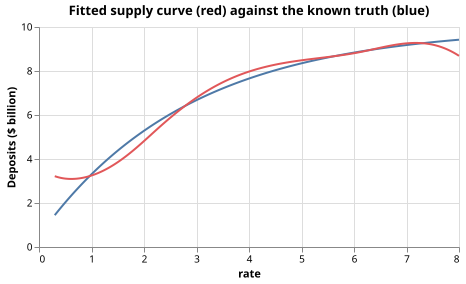

In [4]:
gridframe = pl.DataFrame({
    "y": np.zeros(len(grid)), "rate": grid, "rate_c": grid - rate.mean(),
})
fitted = np.exp(np.asarray(model.predict(newdata=gridframe)).ravel())

fitframe = truth.with_columns(fitted=fitted)

rec_line = alt.Chart(fitframe).mark_line(color="#e15759", strokeWidth=2).encode(
    x="rate:Q", y=alt.Y("fitted:Q", title="Deposits ($ billion)"),
)
true_line = alt.Chart(fitframe).mark_line(color="#4e79a7", strokeWidth=2).encode(
    x="rate:Q", y="deposits:Q",
)
(true_line + rec_line).properties(
    width=420, height=220,
    title="Fitted supply curve (red) against the known truth (blue)"
)

The fitted curve sits on the known truth across the rate range, bending toward
the ceiling without overshooting it. Holding the ceiling is what matters for
the marginal cost: a curve that flattened too early would understate the cost
of the last dollars, and a curve that kept rising would understate the
saturation.


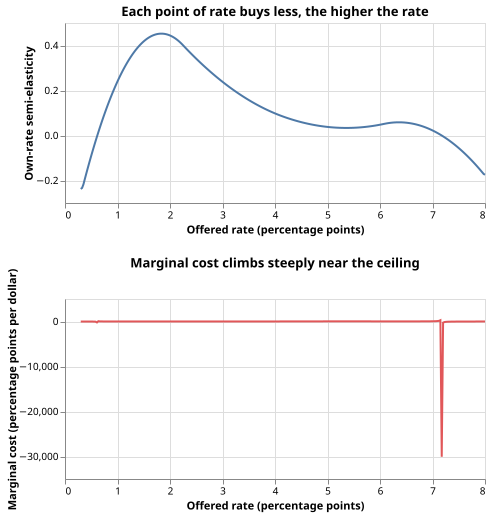

In [5]:
eta_hat = np.gradient(np.log(fitted), grid)
mc_hat = grid + 1.0 / eta_hat

eta_rows = pl.DataFrame({
    "rate": grid,
    "eta": eta_hat,
    "marginal_cost": mc_hat,
})

eta_chart = alt.Chart(eta_rows).mark_line(color="#4e79a7", strokeWidth=2).encode(
    x=alt.X("rate:Q", title="Offered rate (percentage points)"),
    y=alt.Y("eta:Q", title="Own-rate semi-elasticity", scale=alt.Scale(zero=False)),
).properties(width=420, height=180, title="Each point of rate buys less, the higher the rate")

mc_chart = alt.Chart(eta_rows).mark_line(color="#e15759", strokeWidth=2).encode(
    x=alt.X("rate:Q", title="Offered rate (percentage points)"),
    y=alt.Y("marginal_cost:Q", title="Marginal cost (percentage points per dollar)",
            scale=alt.Scale(zero=False)),
).properties(width=420, height=180, title="Marginal cost climbs steeply near the ceiling")

alt.vconcat(eta_chart, mc_chart).resolve_scale(x="shared")

The semi-elasticity $\eta$ (the proportional change in deposits per percentage point of rate, $\partial \log D/\partial r$) falls from above one at low rates to near zero at high
rates, and the marginal cost answers it: from single digits of percentage
points at the low end to tens and beyond as the rate rises. The derivative of the fitted log-balance curve supplies the semi-elasticity;
its reciprocal supplies the repricing component of marginal cost. A bank
planning a deposit campaign needs the marginal-cost reading, because the
average rate it already pays hides how steep the last dollars are.


## Fit to aggregate bank-funding data

The mechanism is bank-level. The question is whether the one public series with
both deposit balances and the rate actually paid — `mb.datasets.bank_funding()`,
the quarterly totals of every insured US bank — can reproduce it. The fit is
the same: the log of interest-bearing deposits against a smooth function of the
paid rate, with log total assets (the size of the banking system) and a linear time trend included as covariates.


In [6]:
funding = mb.datasets.bank_funding()
# Fit the specification stated above and retain the quantities used below.
expense = funding["interest_expense_qtr"].to_numpy()

ib = funding["deposits_interest_bearing"].to_numpy()

paid = expense / ib * 4 * 100

n_obs = funding.height

la = np.log(funding["assets"].to_numpy())

t = np.arange(n_obs, dtype=float)

real_frame = pl.DataFrame({
    "y": np.log(ib),
    "rate": paid,
    "rate_c": paid - paid.mean(),
    "la": la,
    "t_c": t - (n_obs - 1) / 2.0,
})

REAL_FORMULA = (
    "y ~ bols(rate_c, intercept=False) + bbs(rate_c, center=True, df=1)"
    " + bols(la, intercept=False) + bols(t_c, intercept=False)"
)

def fit_real(frame, mstop):
    return mb.gamboost(REAL_FORMULA, data=frame, family=mb.Gaussian(),
                       control=mb.boost_control(mstop=mstop, nu=0.1))


In [7]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    real_folds = mb.cv_weights(n_obs, type="kfold", B=10, seed=7)
    real_full = fit_real(real_frame, 10000)
    real_cv = real_full.cvrisk(folds=real_folds)

real_mstop = int(real_cv.optimal_mstop)

real_model = real_full[:real_mstop]

print(f"{n_obs} quarters, cross-validated mstop {real_mstop}")


137 quarters, cross-validated mstop 9215


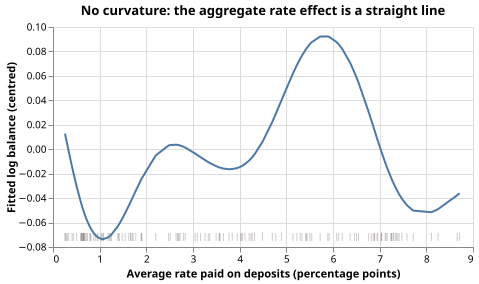

In [8]:
# Two terms read rate_c, so the effects are keyed by term.
pe = real_model.partial_effects(which=["rate_c (bbs)"])
rx, effect = np.asarray(pe["rate_c (bbs)"][0]), np.asarray(pe["rate_c (bbs)"][1])
order = np.argsort(rx)
rx = rx[order] + paid.mean()
effect = effect[order]

real_eta = np.gradient(effect, rx)
real_eta_slope = float(np.polyfit(rx, real_eta, 1)[0])
real_eta_mean = float(real_eta.mean())

eta_flat = f"{abs(real_eta_slope):.2e}"
eta_neg = f"{real_eta_mean * 100:.2f}"

real_curve = pl.DataFrame({"rate": rx, "effect": effect})

alt.Chart(real_curve).mark_line(color="#4e79a7", strokeWidth=2).encode(
    x=alt.X("rate:Q", title="Average rate paid on deposits (percentage points)"),
    y=alt.Y("effect:Q", title="Fitted log balance (centred)",
            scale=alt.Scale(zero=False)),
).properties(
    width=420, height=220,
    title="No curvature: the aggregate rate effect is a straight line"
) + alt.Chart(pl.DataFrame({"rate": paid})).mark_tick(
    color="#79706e", opacity=0.35, size=8, yOffset=100
).encode(x="rate:Q")

The aggregate produces a straight line. The fitted semi-elasticity has no
measurable slope across the rate range — its trend is {eval}`eta_flat` per
percentage point — so there is no saturation to read, and its level is
{eval}`eta_neg`% per percentage point with the *wrong sign*: deposits shrink
as the national paid rate rises. That is the signature of a monetary-policy
relation, not a bank's own supply curve.


## Bank-level and aggregate estimates

The two fits answer two different questions. In the simulation the rate is the
bank's own offered rate, and the balance is that bank's response; the ceiling
is the finite pool of depositors who will move for a higher rate, and the fit
recovers it. In the aggregate the rate is the national average paid rate, which
moves with monetary policy, and the balance is the whole system's. No single
national series varies one bank's rate while the rest of the market holds
still, which is the experiment the supply curve calls for
{cite:p}`drechsler2017deposits`.

Public aggregates do not measure the bank-level saturation curve. A bank
estimating the cost of a
deposit campaign needs its own balances and rates, with enough variation in its
own rate to trace where the response stops growing. The simulated section shows
the shape such data would reveal and the steep cost that follows; the real
section shows why the aggregate record is the wrong instrument for it.


```{bibliography}
:filter: docname in docnames
```
